<a href="https://colab.research.google.com/github/asetya/BigData/blob/master/sobel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# ==============================================================================
# Explicit Sobel Edge Detector for Any Input Image (Colab-ready)
# ==============================================================================

import io
import urllib.request
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import convolve1d

# ------------------------------------------------------------------------------
# 1. Image Loader Supporting Multiple Input Formats
# ------------------------------------------------------------------------------

def load_image(source):
    """
    Accepts:
    - Direct bytes (e.g. from google.colab.files.upload())
    - Web URL (http:// or https://)
    - Local file path ('image.png', 'drive/MyDrive/...')
    - Pre-existing NumPy array

    Returns:
    - img_rgb: 3-channel RGB image for reference visualization
    - img_gray: Grayscale float64 image for gradient computation
    """
    if isinstance(source, np.ndarray):
        img_bgr = source.copy()
    elif isinstance(source, bytes):
        nparr = np.frombuffer(source, np.uint8)
        img_bgr = cv2.imdecode(nparr, cv2.IMREAD_COLOR)
    elif isinstance(source, str) and (source.startswith('http://') or source.startswith('https://')):
        req = urllib.request.Request(source, headers={'User-Agent': 'Mozilla/5.0'})
        with urllib.request.urlopen(req) as resp:
            nparr = np.frombuffer(resp.read(), np.uint8)
            img_bgr = cv2.imdecode(nparr, cv2.IMREAD_COLOR)
    elif isinstance(source, str):
        img_bgr = cv2.imread(source, cv2.IMREAD_COLOR)
    else:
        raise ValueError("Unsupported input format.")

    if img_bgr is None:
        raise ValueError(f"Could not decode image from source: {source}")

    # Convert to RGB for visualization and Grayscale float64 for derivative calculations
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY).astype(np.float64)

    return img_rgb, img_gray


# ------------------------------------------------------------------------------
# 2. Explicit Sobel Edge Detection
# ------------------------------------------------------------------------------

def explicit_sobel_edge_detector(image_input, threshold_ratio=0.15):
    """
    Computes horizontal and vertical gradients explicitly using 1D separable
    convolutions, vector magnitude, orientation, and binary edge thresholding.
    """
    img_rgb, img_gray = load_image(image_input)

    # 1D Separable Kernels
    # Kx = [1, 2, 1]^T * [-1, 0, 1]
    # Ky = [-1, 0, 1]^T * [1, 2, 1]
    smooth_filter = np.array([1, 2, 1], dtype=np.float64)   # Binomial Gaussian smoothing
    diff_filter   = np.array([-1, 0, 1], dtype=np.float64)  # Central finite difference

    # Horizontal Gradient (Ix): Detects vertical edges
    # Convolve rows with diff_filter, then columns with smooth_filter
    diff_x = convolve1d(img_gray, weights=diff_filter, axis=1, mode='reflect')
    Ix     = convolve1d(diff_x,   weights=smooth_filter, axis=0, mode='reflect')

    # Vertical Gradient (Iy): Detects horizontal edges
    # Convolve columns with diff_filter, then rows with smooth_filter
    diff_y = convolve1d(img_gray, weights=diff_filter, axis=0, mode='reflect')
    Iy     = convolve1d(diff_y,   weights=smooth_filter, axis=1, mode='reflect')

    # Gradient Magnitude: ||grad(I)|| = sqrt(Ix^2 + Iy^2)
    magnitude = np.sqrt(Ix**2 + Iy**2)
    max_mag = magnitude.max()

    if max_mag > 0:
        magnitude_norm = (magnitude / max_mag * 255.0).astype(np.uint8)
    else:
        magnitude_norm = np.zeros_like(magnitude, dtype=np.uint8)

    # Gradient Orientation: theta = atan2(Iy, Ix) in degrees [-180, 180]
    orientation_deg = np.degrees(np.arctan2(Iy, Ix))

    # Binary Thresholding
    threshold_value = threshold_ratio * 255.0
    binary_edges = np.where(magnitude_norm >= threshold_value, 255, 0).astype(np.uint8)

    # --------------------------------------------------------------------------
    # Visualization
    # --------------------------------------------------------------------------
    fig, axes = plt.subplots(1, 5, figsize=(22, 5), dpi=120)

    axes[0].imshow(img_rgb)
    axes[0].set_title(f"Input ({img_rgb.shape[1]}x{img_rgb.shape[0]})")
    axes[0].axis('off')

    axes[1].imshow(np.abs(Ix), cmap='gray')
    axes[1].set_title("Horizontal Gradient $|I_x|$\n(Vertical Boundaries)")
    axes[1].axis('off')

    axes[2].imshow(np.abs(Iy), cmap='gray')
    axes[2].set_title("Vertical Gradient $|I_y|$\n(Horizontal Boundaries)")
    axes[2].axis('off')

    axes[3].imshow(magnitude_norm, cmap='magma')
    axes[3].set_title("Gradient Magnitude\n$\sqrt{I_x^2 + I_y^2}$")
    axes[3].axis('off')

    axes[4].imshow(binary_edges, cmap='gray')
    axes[4].set_title(f"Thresholded Edges\n(Cutoff: {int(threshold_value)})")
    axes[4].axis('off')

    plt.tight_layout()
    plt.show()

    return {
        "Ix": Ix,
        "Iy": Iy,
        "magnitude": magnitude_norm,
        "orientation": orientation_deg,
        "binary_edges": binary_edges
    }

<>:114: SyntaxWarning: invalid escape sequence '\s'
<>:114: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_1414/937401233.py:114: SyntaxWarning: invalid escape sequence '\s'
  axes[3].set_title("Gradient Magnitude\n$\sqrt{I_x^2 + I_y^2}$")


Saving 20180915_203000.jpg to 20180915_203000.jpg
Running explicit Sobel on: 20180915_203000.jpg


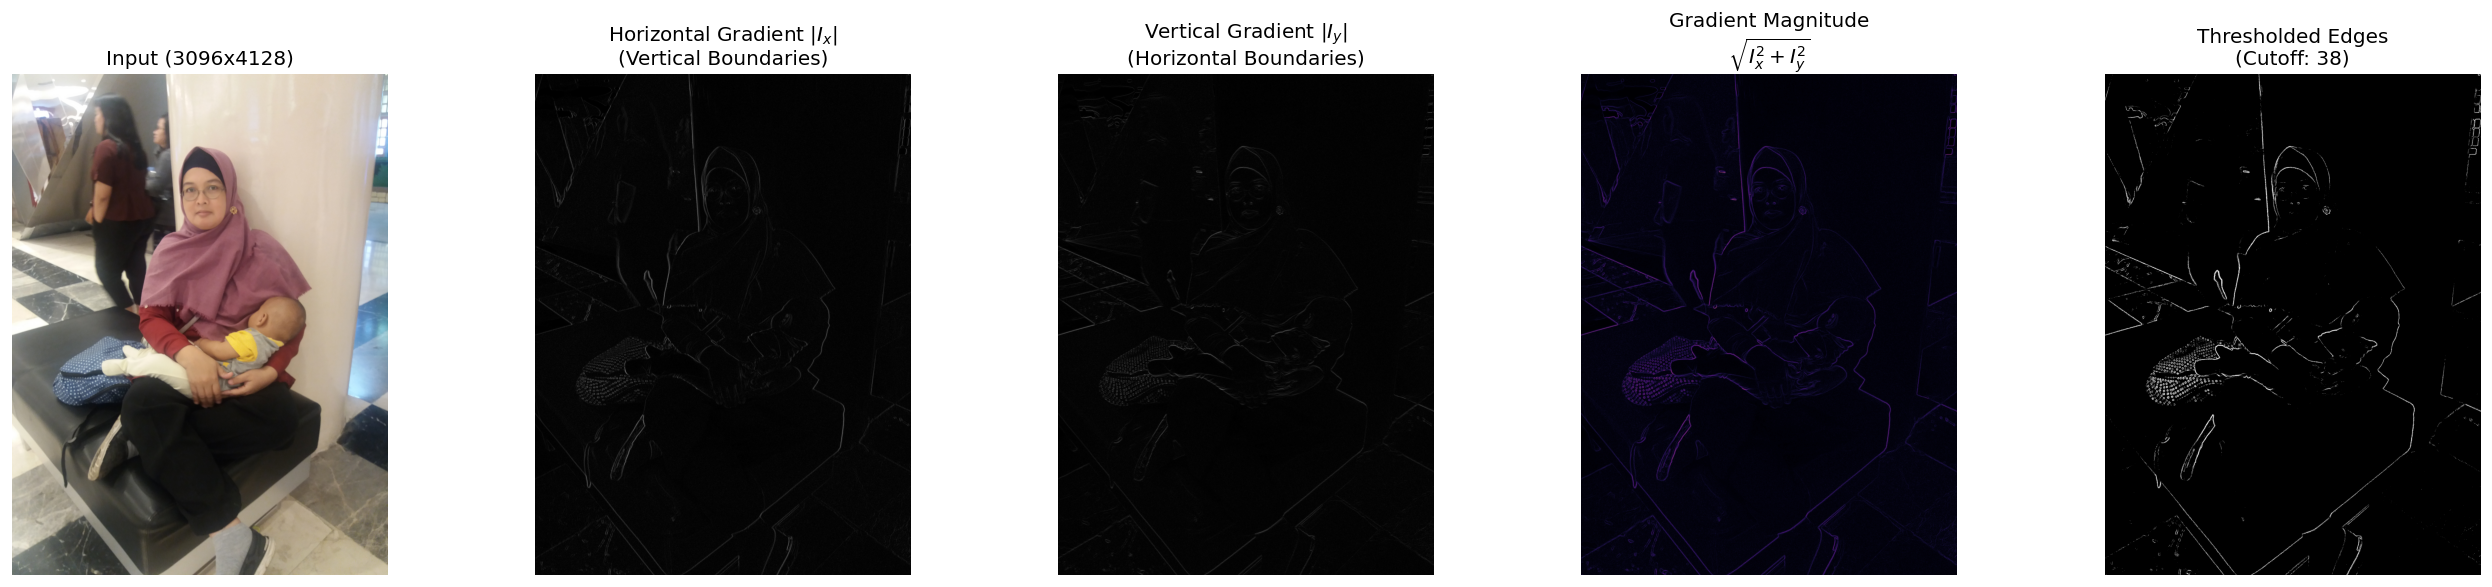

In [4]:
from google.colab import files

uploaded = files.upload()
for filename, file_bytes in uploaded.items():
    print(f"Running explicit Sobel on: {filename}")
    results = explicit_sobel_edge_detector(file_bytes, threshold_ratio=0.15)